In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression

In [2]:
data = pd.read_csv("iris.csv")
data.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [3]:
data["variety"] = data["variety"].astype("category").cat.codes
data.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
x = data[["sepal.length", "sepal.width", "petal.length", "petal.width"]]
y = data["variety"]

In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=0
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)

KNeighborsClassifier()

In [7]:
print("Training Data")

prediction = knn.predict(x_train)
print("\nPrediction")
print(prediction)

print("\nConfusion Matrix Training")
cm = confusion_matrix(y_train, prediction)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_train, prediction)
print(acc)

print("\nPrecision")
precision = precision_score(y_train, prediction, average="weighted")
print(precision)

print("\nRecall")
recall = recall_score(y_train, prediction, average="weighted")
print(recall)

print("\nf1")
f1 = f1_score(y_train, prediction, average="weighted")
print(f1)

Training Data

Prediction
[2 1 0 2 2 1 0 2 1 1 2 0 2 0 0 1 2 2 1 2 1 2 1 1 2 2 1 2 1 2 1 0 2 1 1 1 1
 2 0 0 2 1 0 0 1 0 2 1 0 1 2 1 0 2 2 2 2 0 0 2 2 0 2 0 2 2 0 0 2 0 0 0 1 2
 2 0 0 0 1 1 0 0 1 0 2 1 2 1 0 2 0 2 0 0 2 0 2 1 1 1 2 2 2 2 0 1 2 2 0 1 1
 2 1 0 0 0 2 1 2 0]

Confusion Matrix Training
[[39  0  0]
 [ 0 33  4]
 [ 0  2 42]]

Accuracy Score
0.95

Precision
0.9504968944099379

Recall
0.95

f1
0.9498611111111112


In [8]:
print("Testing Data")

prediction = knn.predict(x_test)
print("\nPrediction")
print(prediction)

print("\nConfusion Matrix Testing")
cm = confusion_matrix(y_test, prediction)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, prediction)
print(acc)

print("\nPrecision")
precision = precision_score(y_test, prediction, average="weighted")
print(precision)

print("\nRecall")
recall = recall_score(y_test, prediction, average="weighted")
print(recall)

print("\nf1")
f1 = f1_score(y_test, prediction, average="weighted")
print(f1)

Testing Data

Prediction
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 2 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0]

Confusion Matrix Testing
[[11  0  0]
 [ 0 12  1]
 [ 0  0  6]]

Accuracy Score
0.9666666666666667

Precision
0.9714285714285714

Recall
0.9666666666666667

f1
0.9672820512820512


In [9]:
slength = float(input("sepal length :"))
swidth = float(input("sepal width :"))
plength = float(input("petal length"))
pwidth = float(input("petal width"))

user_input = pd.DataFrame(
    [[slength, swidth, plength, pwidth]], columns=x.columns
)

prediction = knn.predict(user_input)
variety = ["Setosa", "Versicolor", "Virginica"]

print("Predicted variety:", prediction[0], f"({variety[prediction[0]]})")

sepal length :4
sepal width :6
petal length4
petal width7
Predicted variety: 2 (Virginica)


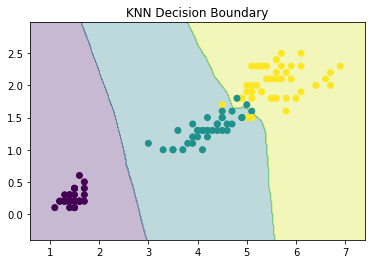

In [10]:
knn_plot = KNeighborsClassifier(n_neighbors=5)
knn_plot.fit(x_train[["petal.length", "petal.width"]], y_train)

a = np.arange(x_train["petal.length"].min() - 0.5,
              x_train["petal.length"].max() + 0.5, 0.02)
b = np.arange(x_train["petal.width"].min() - 0.5,
              x_train["petal.width"].max() + 0.5, 0.02)
xx, yy = np.meshgrid(a, b)

grid = pd.DataFrame({
    "petal.length": xx.ravel(),
    "petal.width": yy.ravel()
})
z = knn_plot.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, z, alpha=0.3)
plt.scatter(x_train["petal.length"], x_train["petal.width"], c=y_train)
plt.title("KNN Decision Boundary")
plt.show()

In [11]:
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(x_train, y_train)

LogisticRegression(max_iter=200)

In [12]:
print("Training Data")

lpred = log_reg.predict(x_train)
print("\nPrediction")
print(lpred)

print("\nConfusion Matrix Training")
cm = confusion_matrix(y_train, lpred)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_train, lpred)
print(acc)

print("\nPrecision")
precision = precision_score(y_train, lpred, average="weighted")
print(precision)

print("\nRecall")
recall = recall_score(y_train, lpred, average="weighted")
print(recall)

print("\nf1")
f1 = f1_score(y_train, lpred, average="weighted")
print(f1)

Training Data

Prediction
[2 1 0 2 2 1 0 2 1 1 2 0 2 0 0 1 2 2 2 2 1 2 1 1 2 2 1 2 1 2 1 0 2 1 1 1 1
 2 0 0 2 1 0 0 1 0 2 1 0 1 2 1 0 2 2 2 2 0 0 2 2 0 2 0 2 2 0 0 2 0 0 0 1 2
 2 0 0 0 1 1 0 0 1 0 2 1 2 1 0 2 0 2 0 0 2 0 2 1 1 1 2 2 1 2 0 1 2 2 0 1 1
 2 1 0 0 0 2 1 2 0]

Confusion Matrix Training
[[39  0  0]
 [ 0 34  3]
 [ 0  1 43]]

Accuracy Score
0.9666666666666667

Precision
0.9672774327122153

Recall
0.9666666666666667

f1
0.9665740740740743


In [13]:
print("Testing Data")

lpred = log_reg.predict(x_test)
print("\nPrediction")
print(lpred)

print("\nConfusion Matrix Testing")
cm = confusion_matrix(y_test, lpred)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, lpred)
print(acc)

print("\nPrecision")
precision = precision_score(y_test, lpred, average="weighted")
print(precision)

print("\nRecall")
recall = recall_score(y_test, lpred, average="weighted")
print(recall)

print("\nf1")
f1 = f1_score(y_test, lpred, average="weighted")
print(f1)

Testing Data

Prediction
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0]

Confusion Matrix Testing
[[11  0  0]
 [ 0 13  0]
 [ 0  0  6]]

Accuracy Score
1.0

Precision
1.0

Recall
1.0

f1
1.0


In [14]:
slength = float(input("sepal length :"))
swidth = float(input("sepal width :"))
plength = float(input("petal length"))
pwidth = float(input("petal width"))

user_input = pd.DataFrame(
    [[slength, swidth, plength, pwidth]], columns=x.columns
)

lpred = log_reg.predict(user_input)
variety = ["Setosa", "Versicolor", "Virginica"]

print("Predicted variety:", lpred[0], f"({variety[lpred[0]]})")

sepal length :56
sepal width :34
petal length56
petal width45
Predicted variety: 2 (Virginica)


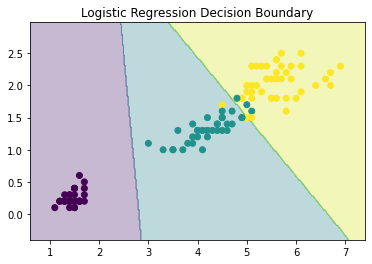

In [15]:
lr_plot = LogisticRegression(max_iter=200)
lr_plot.fit(x_train[["petal.length", "petal.width"]], y_train)

z = lr_plot.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, z, alpha=0.3)
plt.scatter(x_train["petal.length"], x_train["petal.width"], c=y_train)
plt.title("Logistic Regression Decision Boundary")
plt.show()